In [1]:
!pip install GEOparse

In [2]:
import GEOparse
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# GSE161731: COVID-19 vs Influenza vs Healthy blood transcriptomics
# Published in Nature Communications
# This downloads directly from NCBI
gse = GEOparse.get_GEO("GSE161731", destdir="data/")
print(f"Title: {gse.metadata['title'][0]}")
print(f"Samples: {len(gse.gsms)}")

24-May-2026 15:26:56 DEBUG utils - Directory data/ already exists. Skipping.
24-May-2026 15:26:56 INFO GEOparse - File already exist: using local version.
24-May-2026 15:26:56 INFO GEOparse - Parsing data/GSE161731_family.soft.gz: 
24-May-2026 15:26:56 DEBUG GEOparse - DATABASE: GeoMiame
24-May-2026 15:26:56 DEBUG GEOparse - SERIES: GSE161731
24-May-2026 15:26:56 DEBUG GEOparse - PLATFORM: GPL24676
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913486
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913487
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913488
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913489
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913490
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913491
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913492
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913493
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913494
24-May-2026 15:26:56 DEBUG GEOparse - SAMPLE: GSM4913495
24-May-2026 15:26:56 DEBUG G

Title: Dysregulated transcriptional responses to SARS-CoV-2 in the periphery support novel diagnostic approaches
Samples: 198


In [3]:
# Pull metadata from every sample
metadata_list = []
for sample_name, sample in gse.gsms.items():
    sample_info = {"sample_id": sample_name}
    
    # GEO stores metadata as "characteristics" 
    for char in sample.metadata.get("characteristics_ch1", []):
        if ": " in char:
            key, value = char.split(": ", 1)
            sample_info[key.strip()] = value.strip()
    
    # Also grab the title and source
    sample_info["title"] = sample.metadata.get("title", [""])[0]
    sample_info["source"] = sample.metadata.get("source_name_ch1", [""])[0]
    
    metadata_list.append(sample_info)

meta_df = pd.DataFrame(metadata_list)
print(f"Shape: {meta_df.shape}")
print(f"\nColumns: {list(meta_df.columns)}")
print(f"\n{meta_df.head()}")

Shape: (198, 12)

Columns: ['sample_id', 'subject_id', 'age', 'gender', 'race', 'cohort', 'time_since_onset', 'hospitalized', 'tissue', 'batch', 'title', 'source']

    sample_id subject_id age  gender                    race     cohort  \
0  GSM4913486     A1BD46  57  Female  Black/African American  Bacterial   
1  GSM4913487     44DF6B  19    Male  Black/African American  Influenza   
2  GSM4913488     658A11  14    Male                   White  Influenza   
3  GSM4913489     61DE97  21  Female                   White  Influenza   
4  GSM4913490     4D4F7C  50  Female  Black/African American  Influenza   

  time_since_onset hospitalized       tissue batch  \
0               NA           NA  whole blood     1   
1               NA           NA  whole blood     2   
2               NA           NA  whole blood     2   
3               NA           NA  whole blood     1   
4               NA           NA  whole blood     1   

                          title       source  
0           

In [4]:
# What columns do we have?
print("All columns:")
for col in meta_df.columns:
    n_unique = meta_df[col].nunique()
    print(f"  {col}: {n_unique} unique values")

# Show the key grouping variables
print("\n")
for col in meta_df.columns:
    if meta_df[col].nunique() < 15:
        print(f"\n{col}:")
        print(meta_df[col].value_counts())

All columns:
  sample_id: 198 unique values
  subject_id: 155 unique values
  age: 56 unique values
  gender: 3 unique values
  race: 7 unique values
  cohort: 5 unique values
  time_since_onset: 4 unique values
  hospitalized: 3 unique values
  tissue: 1 unique values
  batch: 2 unique values
  title: 198 unique values
  source: 1 unique values



gender:
gender
Male      93
Female    84
NA        21
Name: count, dtype: int64

race:
race
White                               121
Black/African American               40
Asian                                27
Unknown/Not reported                  5
Native Hawaiian/Pacific Islander      2
Other/More than one race              2
American Indian/Alaska Native         1
Name: count, dtype: int64

cohort:
cohort
COVID-19     77
CoV other    61
Bacterial    24
healthy      19
Influenza    17
Name: count, dtype: int64

time_since_onset:
time_since_onset
NA        121
middle     36
late       22
early      19
Name: count, dtype: int64

hospitaliz

In [5]:
# Fix data types
meta_df["age"] = pd.to_numeric(meta_df["age"], errors="coerce")

# Replace "NA" strings with actual NaN
meta_df = meta_df.replace("NA", np.nan)

# Check group sizes
print("Cohort sizes:")
print(meta_df["cohort"].value_counts())
print(f"\nTotal samples: {meta_df.shape[0]}")
print(f"\nAge range: {meta_df['age'].min():.0f} - {meta_df['age'].max():.0f}")

Cohort sizes:
cohort
COVID-19     77
CoV other    61
Bacterial    24
healthy      19
Influenza    17
Name: count, dtype: int64

Total samples: 198

Age range: 0 - 88


/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15491/4060128364.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=meta_df, x="cohort", palette=palette,
/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15491/4060128364.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=meta_df, x="cohort", y="age", palette=palette,


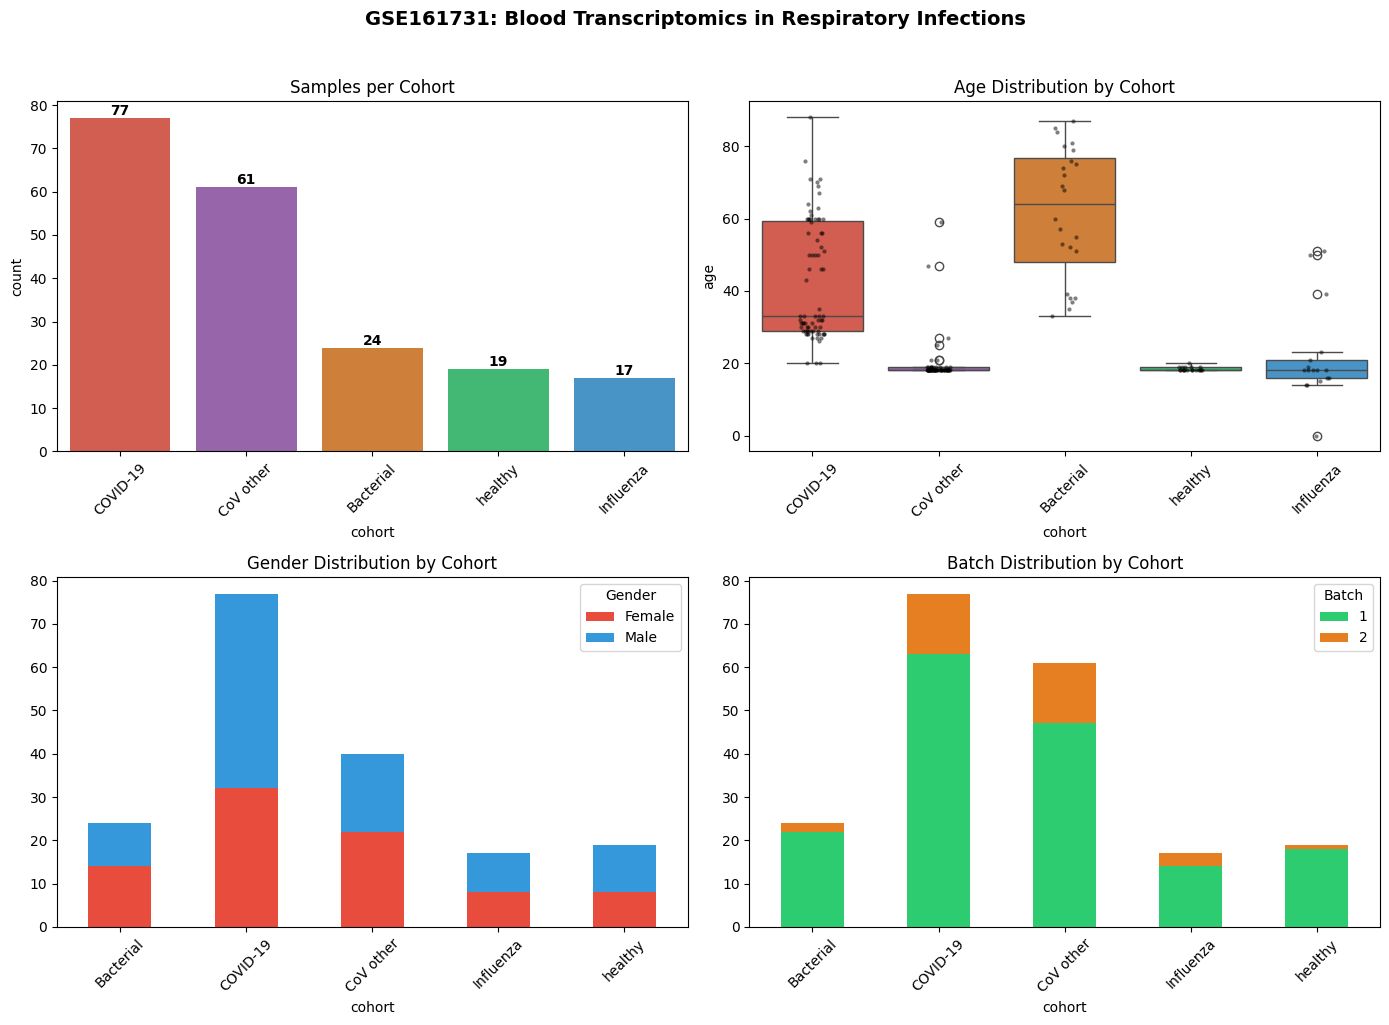

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Samples per cohort
palette = {"COVID-19": "#e74c3c", "Influenza": "#3498db", "Bacterial": "#e67e22", 
           "CoV other": "#9b59b6", "healthy": "#2ecc71"}

sns.countplot(data=meta_df, x="cohort", palette=palette, 
              order=meta_df["cohort"].value_counts().index, ax=axes[0, 0])
axes[0, 0].set_title("Samples per Cohort")
axes[0, 0].tick_params(axis='x', rotation=45)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())}', 
                        (p.get_x() + p.get_width()/2., p.get_height()),
                        ha='center', va='bottom', fontweight='bold')

# Age distribution by cohort
sns.boxplot(data=meta_df, x="cohort", y="age", palette=palette,
            order=meta_df["cohort"].value_counts().index, ax=axes[0, 1])
sns.stripplot(data=meta_df, x="cohort", y="age", color="black", 
              size=3, alpha=0.5, order=meta_df["cohort"].value_counts().index, ax=axes[0, 1])
axes[0, 1].set_title("Age Distribution by Cohort")
axes[0, 1].tick_params(axis='x', rotation=45)

# Gender distribution
gender_counts = meta_df.groupby(["cohort", "gender"]).size().unstack(fill_value=0)
gender_counts.plot(kind="bar", stacked=True, ax=axes[1, 0], 
                   color=["#e74c3c", "#3498db", "#95a5a6"])
axes[1, 0].set_title("Gender Distribution by Cohort")
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].legend(title="Gender")

# Batch distribution
batch_counts = meta_df.groupby(["cohort", "batch"]).size().unstack(fill_value=0)
batch_counts.plot(kind="bar", stacked=True, ax=axes[1, 1],
                  color=["#2ecc71", "#e67e22"])
axes[1, 1].set_title("Batch Distribution by Cohort")
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].legend(title="Batch")

plt.suptitle("GSE161731: Blood Transcriptomics in Respiratory Infections", 
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/08_cohort_overview_GSE161731.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# Look at one sample to understand the structure
sample_name = list(gse.gsms.keys())[0]
sample = gse.gsms[sample_name]

print(f"Sample: {sample_name}")
print(f"\nTable columns: {list(sample.table.columns)}")
print(f"\nFirst few rows:")
print(sample.table.head())
print(f"\nTable shape: {sample.table.shape}")

Sample: GSM4913486

Table columns: []

First few rows:
Empty DataFrame
Columns: []
Index: []

Table shape: (0, 0)


In [8]:
# Check what supplementary files exist for this dataset
print("Dataset supplementary files:")
for key, value in gse.metadata.items():
    if "supplementary" in key.lower():
        for v in value:
            print(f"  {v}")

Dataset supplementary files:
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_counts.csv.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_counts_key.csv.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_key.csv.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_xpr_nlcpm.csv.gz
  ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_xpr_tpm_geo.txt.gz


In [9]:
import urllib.request
import os

os.makedirs("data", exist_ok=True)

# Download raw counts (this is what DESeq2 needs)
url_counts = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_counts.csv.gz"
url_key = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE161nnn/GSE161731/suppl/GSE161731_counts_key.csv.gz"

print("Downloading counts matrix...")
urllib.request.urlretrieve(url_counts, "data/GSE161731_counts.csv.gz")
print("Downloading counts key...")
urllib.request.urlretrieve(url_key, "data/GSE161731_counts_key.csv.gz")
print("Done!")

Done!


In [10]:
# Load the count matrix
counts = pd.read_csv("data/GSE161731_counts.csv.gz", index_col=0)
counts_key = pd.read_csv("data/GSE161731_counts_key.csv.gz", index_col=0)

print(f"Counts matrix shape: {counts.shape}")
print(f"Rows (genes): {counts.shape[0]}")
print(f"Columns (samples): {counts.shape[1]}")

print(f"\nFirst 5 genes x 3 samples:")
print(counts.iloc[:5, :3])

print(f"\nCounts key shape: {counts_key.shape}")
print(f"\nCounts key head:")
print(counts_key.head())

print(f"\nValue range: {counts.min().min()} to {counts.max().max()}")
print(f"These look like {'raw counts' if counts.min().min() >= 0 and counts.dtypes.iloc[0] in ['int64', 'float64'] else 'normalized values'}")

Counts matrix shape: (60675, 201)
Rows (genes): 60675
Columns (samples): 201

First 5 genes x 3 samples:
                 94189  DU09-03S0000604  DU09-03S0000611
ENSG00000223972      0                0                3
ENSG00000227232    393              142              152
ENSG00000278267      0               22               29
ENSG00000243485      0                0                0
ENSG00000274890      0                0                0

Counts key shape: (198, 8)

Counts key head:
                subject_id age  gender                    race     cohort  \
rna_id                                                                      
94189               A1BD46  57  Female  Black/African American  Bacterial   
DU09-03S0000604     44DF6B  19    Male  Black/African American  Influenza   
DU09-03S0000611     658A11  14    Male                   White  Influenza   
105920              61DE97  21  Female                   White  Influenza   
DU09-03S0000774     4D4F7C  50  Female  Black

In [11]:
# The counts_key index (rna_id) matches the column names in the counts matrix
# Let's verify
counts_samples = set(counts.columns)
key_samples = set(counts_key.index)

print(f"Samples in counts: {len(counts_samples)}")
print(f"Samples in key: {len(key_samples)}")
print(f"Overlap: {len(counts_samples & key_samples)}")
print(f"In counts but not key: {counts_samples - key_samples}")

# Use counts_key as our metadata (it's cleaner than the GEO metadata)
meta = counts_key.copy()
meta["rna_id"] = meta.index
meta["age"] = pd.to_numeric(meta["age"], errors="coerce")

print(f"\nCohort sizes:")
print(meta["cohort"].value_counts())

Samples in counts: 201
Samples in key: 198
Overlap: 198
In counts but not key: {'DU09-02S0000150_batch2', 'DU09-02S0000158_batch2', 'DU09-02S0000154_batch2'}

Cohort sizes:
cohort
COVID-19     77
CoV other    61
Bacterial    24
healthy      19
Influenza    17
Name: count, dtype: int64


In [12]:
# Keep only samples that are in both counts and metadata
shared_samples = list(counts_samples & key_samples)
counts_clean = counts[shared_samples]
meta_clean = meta.loc[shared_samples].copy()

print(f"Clean counts: {counts_clean.shape}")
print(f"Clean metadata: {meta_clean.shape}")

# Basic gene filtering: keep genes detected in at least 10% of samples
min_samples = int(0.1 * counts_clean.shape[1])
gene_detection = (counts_clean > 0).sum(axis=1)
genes_keep = gene_detection[gene_detection >= min_samples].index
counts_filtered = counts_clean.loc[genes_keep]

print(f"\nBefore filtering: {counts_clean.shape[0]} genes")
print(f"After filtering (detected in >= {min_samples} samples): {counts_filtered.shape[0]} genes")
print(f"Removed {counts_clean.shape[0] - counts_filtered.shape[0]} low-expression genes")

Clean counts: (60675, 198)
Clean metadata: (198, 9)

Before filtering: 60675 genes
After filtering (detected in >= 19 samples): 28996 genes
Removed 31679 low-expression genes


/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15491/3273857765.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=meta_clean, x="cohort", y="library_size", palette="Set2", ax=axes[0, 0])
/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15491/3273857765.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=meta_clean, x="cohort", y="genes_detected", palette="Set2", ax=axes[1, 0])


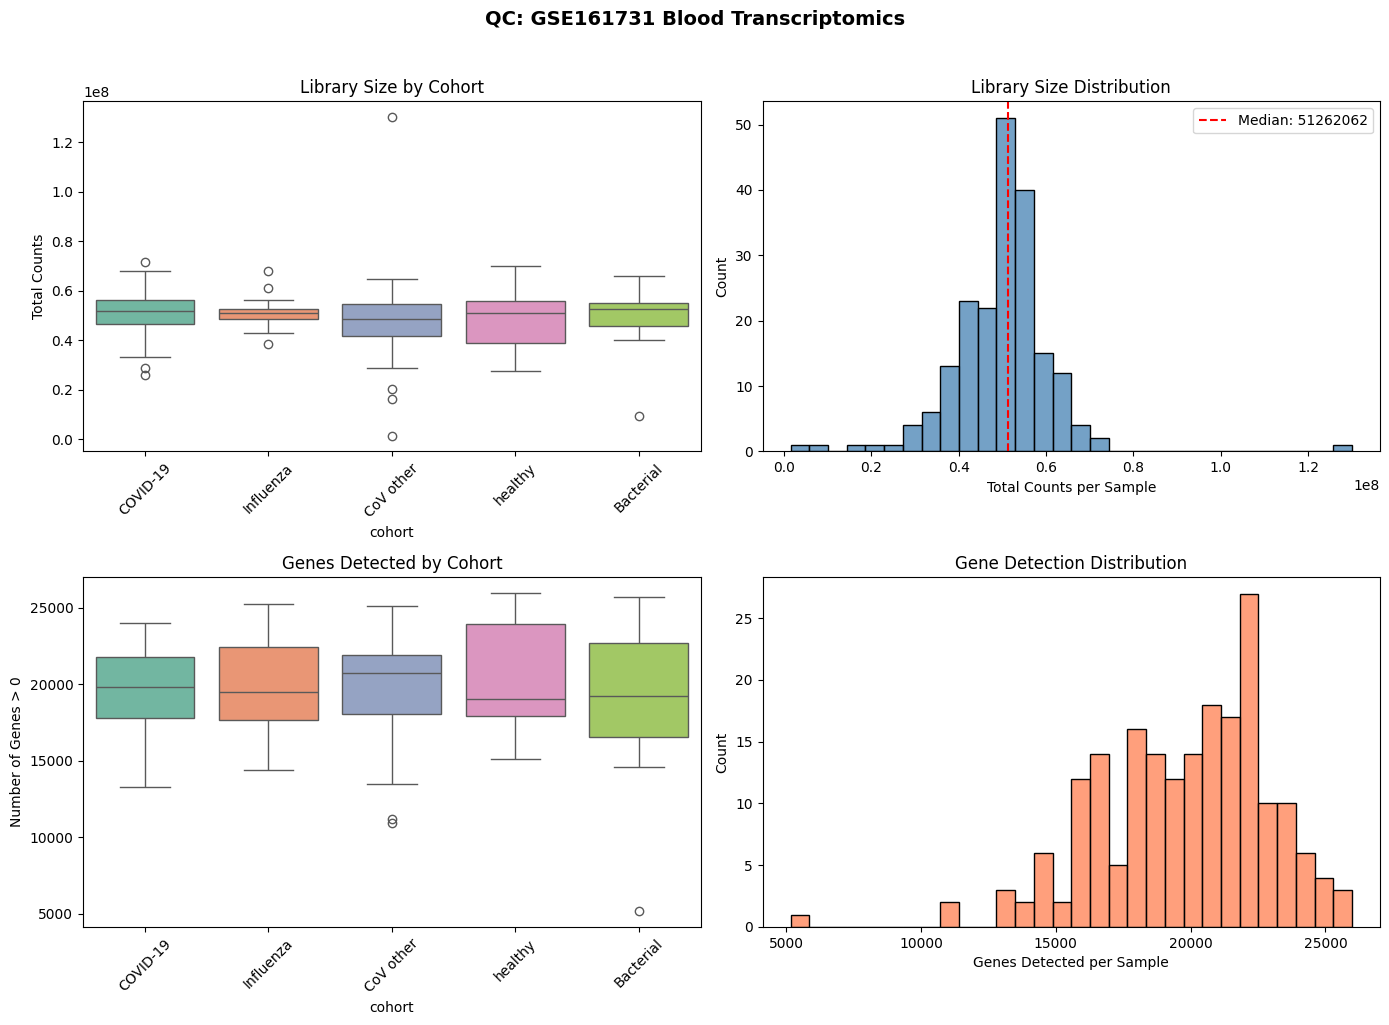

Potential outlier samples (library size < 1M):
None found


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Library size per sample
lib_sizes = counts_filtered.sum(axis=0)
meta_clean["library_size"] = lib_sizes[meta_clean.index].values

sns.boxplot(data=meta_clean, x="cohort", y="library_size", palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("Library Size by Cohort")
axes[0, 0].set_ylabel("Total Counts")
axes[0, 0].tick_params(axis='x', rotation=45)

# Library size distribution
sns.histplot(lib_sizes, bins=30, color="steelblue", ax=axes[0, 1])
axes[0, 1].set_title("Library Size Distribution")
axes[0, 1].set_xlabel("Total Counts per Sample")
axes[0, 1].axvline(lib_sizes.median(), color="red", linestyle="--", label=f"Median: {lib_sizes.median():.0f}")
axes[0, 1].legend()

# Genes detected per sample
genes_detected = (counts_filtered > 0).sum(axis=0)
meta_clean["genes_detected"] = genes_detected[meta_clean.index].values

sns.boxplot(data=meta_clean, x="cohort", y="genes_detected", palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("Genes Detected by Cohort")
axes[1, 0].set_ylabel("Number of Genes > 0")
axes[1, 0].tick_params(axis='x', rotation=45)

# Genes detected distribution
sns.histplot(genes_detected, bins=30, color="coral", ax=axes[1, 1])
axes[1, 1].set_title("Gene Detection Distribution")
axes[1, 1].set_xlabel("Genes Detected per Sample")

plt.suptitle("QC: GSE161731 Blood Transcriptomics", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/09_qc_library_size.png", dpi=300, bbox_inches="tight")
plt.show()

# Flag potential outliers
print("Potential outlier samples (library size < 1M):")
outliers = meta_clean[meta_clean["library_size"] < 1_000_000]
if len(outliers) > 0:
    print(outliers[["rna_id", "cohort", "library_size", "genes_detected"]])
else:
    print("None found")

In [14]:
!pip install scikit-learn

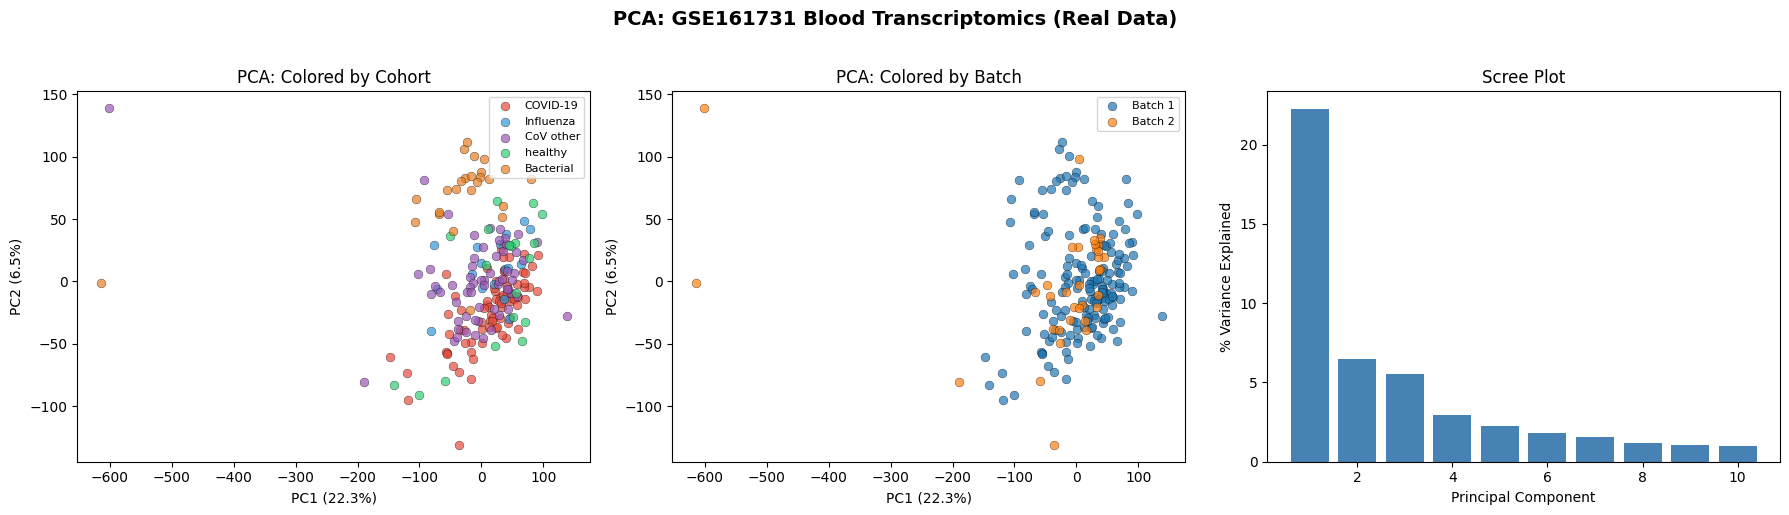

PC1 + PC2 explain 28.8% of variance


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Log-transform counts
log_counts = np.log2(counts_filtered + 1)

# Transpose: PCA wants samples as rows, genes as columns
X = log_counts.T

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Run PCA
pca = PCA(n_components=10)
pcs = pca.fit_transform(X_scaled)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

palette = {"COVID-19": "#e74c3c", "Influenza": "#3498db", "Bacterial": "#e67e22",
           "CoV other": "#9b59b6", "healthy": "#2ecc71"}

# PC1 vs PC2 colored by cohort
for cohort in meta_clean["cohort"].unique():
    mask = meta_clean["cohort"].values == cohort
    axes[0].scatter(pcs[mask, 0], pcs[mask, 1], c=palette.get(cohort, "gray"),
                    label=cohort, s=40, alpha=0.7, edgecolors="black", linewidth=0.3)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("PCA: Colored by Cohort")
axes[0].legend(fontsize=8)

# PC1 vs PC2 colored by batch
for batch in meta_clean["batch"].unique():
    mask = meta_clean["batch"].values == batch
    axes[1].scatter(pcs[mask, 0], pcs[mask, 1], label=f"Batch {batch}",
                    s=40, alpha=0.7, edgecolors="black", linewidth=0.3)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[1].set_title("PCA: Colored by Batch")
axes[1].legend(fontsize=8)

# Scree plot
axes[2].bar(range(1, 11), pca.explained_variance_ratio_ * 100, color="steelblue")
axes[2].set_xlabel("Principal Component")
axes[2].set_ylabel("% Variance Explained")
axes[2].set_title("Scree Plot")

plt.suptitle("PCA: GSE161731 Blood Transcriptomics (Real Data)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/10_pca_real_data.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"PC1 + PC2 explain {(pca.explained_variance_ratio_[0] + pca.explained_variance_ratio_[1])*100:.1f}% of variance")

In [16]:
# Find the outlier samples (PC1 < -400)
outlier_mask = pcs[:, 0] < -400
outlier_samples = meta_clean[outlier_mask]

print("Outlier samples (PC1 < -400):")
print(outlier_samples[["rna_id", "cohort", "age", "gender", "library_size", "genes_detected", "batch"]])

print(f"\nFor comparison, median library size: {meta_clean['library_size'].median():.0f}")
print(f"Median genes detected: {meta_clean['genes_detected'].median():.0f}")

Outlier samples (PC1 < -400):
        rna_id     cohort   age  gender  library_size  genes_detected  batch
rna_id                                                                      
94478    94478  Bacterial  68.0  Female       9365029            5170      2
434741  434741  CoV other  18.0  Female       1545144           10910      2

For comparison, median library size: 51262062
Median genes detected: 20100


In [17]:
# Remove outlier samples
outlier_ids = outlier_samples.index.tolist()
print(f"Removing {len(outlier_ids)} outlier samples: {outlier_ids}")

meta_clean = meta_clean[~meta_clean.index.isin(outlier_ids)]
counts_filtered = counts_filtered[[c for c in counts_filtered.columns if c not in outlier_ids]]

print(f"Remaining samples: {meta_clean.shape[0]}")
print(f"Cohort sizes after removal:")
print(meta_clean["cohort"].value_counts())

Removing 2 outlier samples: ['94478', '434741']
Remaining samples: 196
Cohort sizes after removal:
cohort
COVID-19     77
CoV other    60
Bacterial    23
healthy      19
Influenza    17
Name: count, dtype: int64


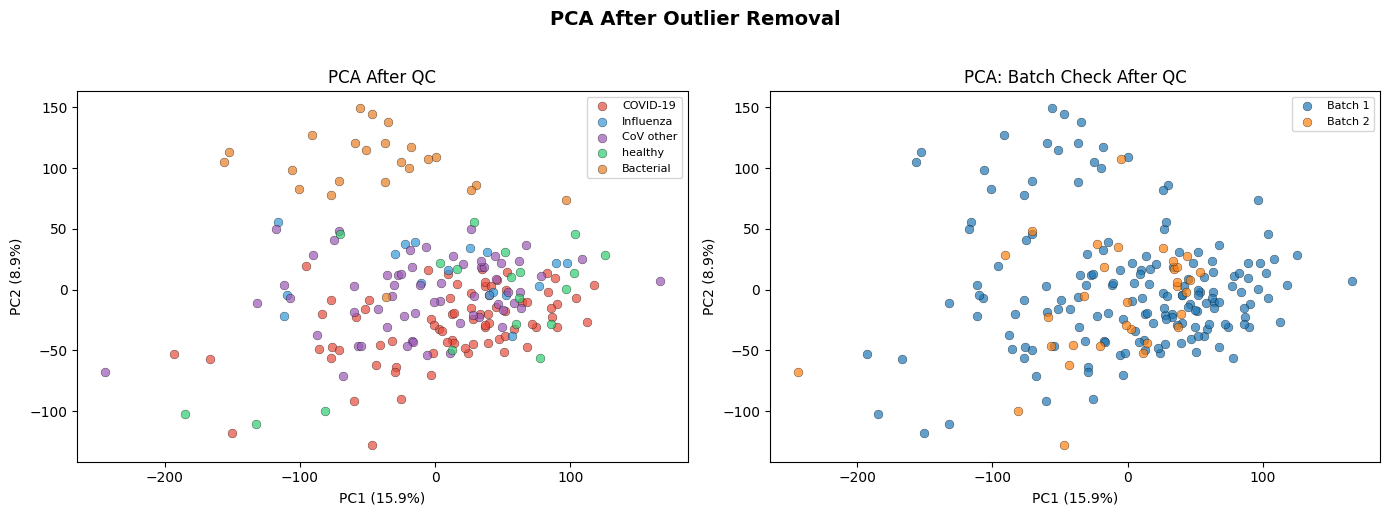

PC1: 15.9%
PC2: 8.9%


In [18]:
# Redo PCA
log_counts = np.log2(counts_filtered + 1)
X = log_counts.T
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=10)
pcs = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette = {"COVID-19": "#e74c3c", "Influenza": "#3498db", "Bacterial": "#e67e22",
           "CoV other": "#9b59b6", "healthy": "#2ecc71"}

for cohort in meta_clean["cohort"].unique():
    mask = meta_clean["cohort"].values == cohort
    axes[0].scatter(pcs[mask, 0], pcs[mask, 1], c=palette.get(cohort, "gray"),
                    label=cohort, s=40, alpha=0.7, edgecolors="black", linewidth=0.3)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("PCA After QC")
axes[0].legend(fontsize=8)

for batch in meta_clean["batch"].unique():
    mask = meta_clean["batch"].values == batch
    axes[1].scatter(pcs[mask, 0], pcs[mask, 1], label=f"Batch {batch}",
                    s=40, alpha=0.7, edgecolors="black", linewidth=0.3)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[1].set_title("PCA: Batch Check After QC")
axes[1].legend(fontsize=8)

plt.suptitle("PCA After Outlier Removal", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/11_pca_after_qc.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")

In [19]:
# Save everything for later modules
counts_filtered.to_csv("results/GSE161731_counts_filtered.csv")
meta_clean.to_csv("results/GSE161731_metadata_clean.csv")

print(f"Saved filtered counts: {counts_filtered.shape}")
print(f"Saved clean metadata: {meta_clean.shape}")
print(f"\nFinal cohort sizes:")
print(meta_clean["cohort"].value_counts())
print(f"\nThis dataset is now ready for DESeq2 in Module 4")

Saved filtered counts: (28996, 196)
Saved clean metadata: (196, 11)

Final cohort sizes:
cohort
COVID-19     77
CoV other    60
Bacterial    23
healthy      19
Influenza    17
Name: count, dtype: int64

This dataset is now ready for DESeq2 in Module 4
